# Laboratorium 4 — CNN i MLP na CIFAR-10
**Autor:** Oskar Pietrzak  
**Cel:** porównanie accuracy, liczby parametrów i czasu uczenia.

W Colabie wybierz **Środowisko wykonawcze → Zmień typ środowiska → GPU**.
Notebook korzysta z GPU, jeśli jest dostępne. Zapisane wyniki uzyskano na CPU.
Uruchom komórki po kolei. Przy ponownym uruchomieniu powstaną aktualne pliki `wyniki.csv` i `accuracy.png`.

In [ ]:
%pip install -q torch torchvision matplotlib

## 1. Biblioteki i konfiguracja

In [1]:
import copy
import csv
import platform
import time
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS, BATCH_SIZE, LR = 10, 128, 0.001
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Sprzęt:", torch.cuda.get_device_name(0) if device.type == "cuda"
      else platform.processor() or platform.machine(), "| urządzenie:", device)

PyTorch: 2.15.0+cpu | torchvision: 0.29.2+cpu
Sprzęt: x86_64 | urządzenie: cpu


## 2. Dane
Pełny CIFAR-10: 45 000 obrazów treningowych, 5 000 walidacyjnych i 10 000 testowych.
Wspólna normalizacja, bez augmentacji. Podział i kolejność minibatchy są takie same dla obu modeli.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])
dataset = torchvision.datasets.CIFAR10("data", train=True, download=True,
                                       transform=transform)
test = torchvision.datasets.CIFAR10("data", train=False, download=True,
                                    transform=transform)
train, val = random_split(dataset, [45000, 5000],
                          generator=torch.Generator().manual_seed(42))
val_loader = DataLoader(val, batch_size=BATCH_SIZE)
test_loader = DataLoader(test, batch_size=BATCH_SIZE)

## 3. Modele

In [3]:
models = {
    "MLP": nn.Sequential(
        nn.Flatten(),
        nn.Linear(3 * 32 * 32, 512), nn.ReLU(),
        nn.Linear(512, 256), nn.ReLU(),
        nn.Linear(256, 10)
    ),
    "CNN": nn.Sequential(
        nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 8 * 8, 64), nn.ReLU(),
        nn.Linear(64, 10)
    )
}

## 4. Trening i końcowa ocena
Oba modele: Adam, LR = 0,001, batch size = 128, 10 epok, CrossEntropyLoss.
Wybór stanu modelu odbywa się według najwyższej accuracy walidacyjnej
(przy remisie wcześniejsza epoka). Test jest oceniany raz dla każdego modelu,
po wyborze stanu. Czas obejmuje trening, walidację i zapamiętanie najlepszego stanu;
nie obejmuje pobrania danych ani końcowego testu.

In [4]:
def accuracy(model, loader):
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    return correct / len(loader.dataset)


history, results = {}, []
for name, model in models.items():
    torch.manual_seed(42)
    train_loader = DataLoader(
        train, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(42)
    )
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()
    history[name] = []
    best_acc, best_epoch = -1, 0
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
        val_acc = accuracy(model, val_loader)
        history[name].append(val_acc)
        if val_acc > best_acc:
            best_acc, best_epoch = val_acc, epoch
            best_state = copy.deepcopy(model.state_dict())
        print(f"{name}, epoka {epoch}: accuracy walidacyjna = {val_acc:.2%}")
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    model.load_state_dict(best_state)
    test_acc = accuracy(model, test_loader)
    results.append([name, sum(p.numel() for p in model.parameters()),
                    test_acc * 100, elapsed, best_epoch, best_acc * 100])

MLP, epoka 1: accuracy walidacyjna = 47.24%
MLP, epoka 2: accuracy walidacyjna = 48.40%
MLP, epoka 3: accuracy walidacyjna = 50.42%
MLP, epoka 4: accuracy walidacyjna = 50.44%
MLP, epoka 5: accuracy walidacyjna = 51.06%
MLP, epoka 6: accuracy walidacyjna = 52.52%
MLP, epoka 7: accuracy walidacyjna = 51.90%
MLP, epoka 8: accuracy walidacyjna = 51.10%
MLP, epoka 9: accuracy walidacyjna = 52.70%
MLP, epoka 10: accuracy walidacyjna = 53.46%
CNN, epoka 1: accuracy walidacyjna = 53.24%
CNN, epoka 2: accuracy walidacyjna = 60.90%
CNN, epoka 3: accuracy walidacyjna = 64.10%
CNN, epoka 4: accuracy walidacyjna = 65.64%
CNN, epoka 5: accuracy walidacyjna = 67.14%
CNN, epoka 6: accuracy walidacyjna = 68.00%
CNN, epoka 7: accuracy walidacyjna = 68.42%
CNN, epoka 8: accuracy walidacyjna = 69.40%
CNN, epoka 9: accuracy walidacyjna = 69.88%
CNN, epoka 10: accuracy walidacyjna = 70.28%


## 5. Tabela wyników i wspólny wykres accuracy

Model   Parametry   Test [%]   Czas [s]   Epoka
MLP       1707274      53.23       79.4      10
CNN        136874      69.26      106.0      10


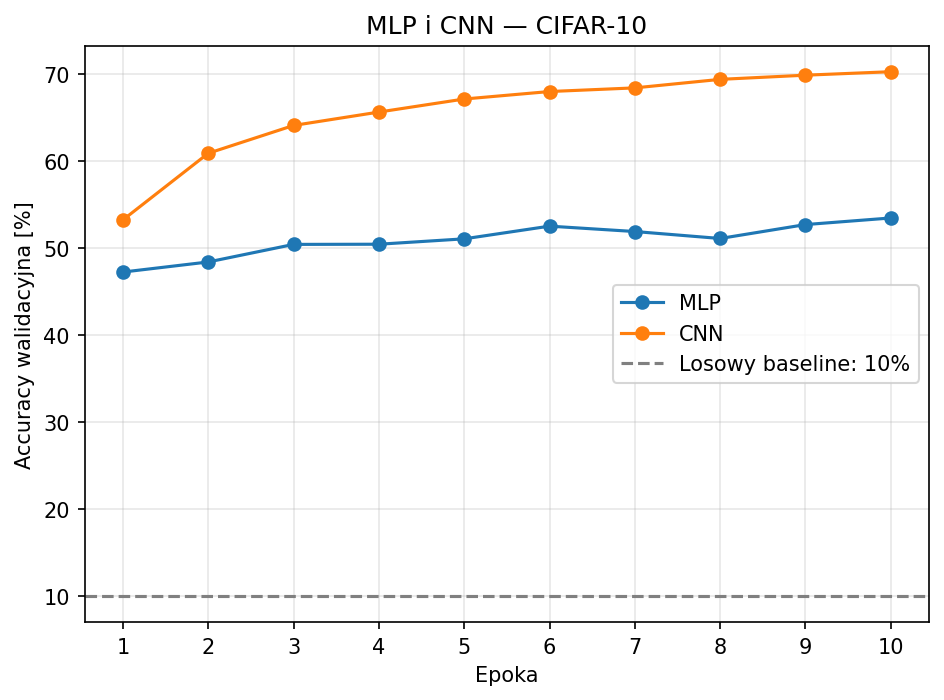

In [5]:
with open("wyniki.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Model", "Parametry", "Accuracy_test_pct", "Czas_s",
                     "Wybrana_epoka", "Accuracy_val_pct"])
    writer.writerows(results)

print(f"{'Model':<6} {'Parametry':>10} {'Test [%]':>10} {'Czas [s]':>10} {'Epoka':>7}")
for name, params, test_acc, elapsed, epoch, val_acc in results:
    print(f"{name:<6} {params:>10} {test_acc:>10.2f} {elapsed:>10.1f} {epoch:>7}")

for name, values in history.items():
    plt.plot(range(1, EPOCHS + 1), [100 * v for v in values], "o-", label=name)
plt.axhline(10, color="gray", linestyle="--", label="Losowy baseline: 10%")
plt.xlabel("Epoka")
plt.ylabel("Accuracy walidacyjna [%]")
plt.title("MLP i CNN — CIFAR-10")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("accuracy.png", dpi=180)
plt.show()

## 6. Interpretacja
Sploty wykorzystują lokalne sąsiedztwo pikseli i współdzielą wagi w całym obrazie.
MLP po spłaszczeniu obrazu nie narzuca takiej struktury połączeń.
Mniejsza liczba parametrów CNN nie oznacza krótszego treningu: te same filtry
są stosowane w wielu położeniach. O przewadze jakościowej decyduje końcowy test;
wyniki, ograniczenia i wnioski opisano w `sprawozdanie_lab4.md`.